# 01 - Data and graph construction (Panama Papers)

**Goal:** load the ICIJ Offshore Leaks data, keep the Panama Papers subset, build the bipartite graph and the weighted entity projection, and report the basic statistics.

Steps:
1. Load and filter the data
2. Inspect node and relationship types
3. Build the bipartite graph
4. Build the entity projection (hub cap)
5. Basic statistics (nodes, edges, type, density)
6. Degree distributions
7. Conclusions and choices to justify in the report

Source: ICIJ Offshore Leaks Database (ODbL 1.0 / CC BY-SA 3.0), bulk CSV generated 2026-09-09.

In [1]:
import sys, pickle, json
sys.path.insert(0, "..")
import numpy as np, pandas as pd, networkx as nx
import matplotlib.pyplot as plt
from src.load import load_panama, PROC
from src.graph import edges_entity_connector, build_bipartite, build_projection, stats, CAP
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FIG = "../figures/"


## 0. The raw data: what ICIJ publishes

The ICIJ Offshore Leaks Database is a **graph stored as CSV files**: one file per node type, plus one file of links.

| File | What a row is | Examples |
|---|---|---|
| `nodes-entities.csv` | An offshore company, trust or foundation | a BVI company |
| `nodes-officers.csv` | A person or company that owns, directs or benefits from an entity | a shareholder, a director, a nominee |
| `nodes-intermediaries.csv` | A law firm, bank or agent that set the structure up | Mossack Fonseca clients' go-betweens |
| `nodes-addresses.csv` | A postal address | a registered address |
| `nodes-others.csv` | Rare special cases | not used |
| `relationships.csv` | A link between two nodes | `officer_of`, `intermediary_of`, `registered_address`... |

Keys:
- `node_id`: unique number of a node, shared by all node files. A relationship is just a pair `(node_id_start, node_id_end)` plus a type.
- `sourceID`: the leak a row comes from (Panama Papers, Paradise Papers, Pandora Papers, Bahamas Leaks, Offshore Leaks). This column lets us keep Panama Papers only.
- `rel_type`: the nature of a link.

In [2]:
from pathlib import Path
RAW = Path("../data/raw")
for f, cols in [("nodes-entities.csv", ["node_id","name","jurisdiction_description","status","sourceID"]),
                ("nodes-officers.csv", ["node_id","name","countries","sourceID"]),
                ("nodes-intermediaries.csv", ["node_id","name","countries","sourceID"]),
                ("nodes-addresses.csv", ["node_id","address","countries","sourceID"]),
                ("relationships.csv", ["node_id_start","node_id_end","rel_type","sourceID"])]:
    print("==", f)
    display(pd.read_csv(RAW / f, usecols=cols, nrows=3))

== nodes-entities.csv


,node_id,name,jurisdiction_description,status,sourceID
0,10000001,"TIANSHENG INDUSTRY AND TRADING CO., LTD.",Samoa,Defaulted,Panama Papers
1,10000002,"NINGBO SUNRISE ENTERPRISES UNITED CO., LTD.",Samoa,Defaulted,Panama Papers
2,10000003,"HOTFOCUS CO., LTD.",Samoa,Defaulted,Panama Papers


== nodes-officers.csv


,node_id,name,countries,sourceID
0,12000001,KIM SOO IN,South Korea,Panama Papers
1,12000002,Tian Yuan,China,Panama Papers
2,12000003,GREGORY JOHN SOLOMON,Australia,Panama Papers


== nodes-intermediaries.csv


,node_id,name,countries,sourceID
0,11000001,"MICHAEL PAPAGEORGE, MR.",South Africa,Panama Papers
1,11000002,CORFIDUCIA ANSTALT,Liechtenstein,Panama Papers
2,11000003,"DAVID, RONALD",Monaco,Panama Papers


== nodes-addresses.csv


,node_id,address,countries,sourceID
0,24000001,"ANNEX FREDERICK & SHIRLEY STS, P.O. BOX N-4805...",Bahamas,Bahamas Leaks
1,24000002,"SUITE E-2,UNION COURT BUILDING, P.O. BOX N-818...",Bahamas,Bahamas Leaks
2,24000003,"LYFORD CAY HOUSE, LYFORD CAY, P.O. BOX N-7785,...",Bahamas,Bahamas Leaks


== relationships.csv


,node_id_start,node_id_end,rel_type,sourceID
0,10000035,14095990,registered_address,Panama Papers
1,10000044,14091035,registered_address,Panama Papers
2,10000055,14095990,registered_address,Panama Papers


### Which leaks, and which relationship types? (whole database)

In [3]:
ent_all = pd.read_csv(RAW / "nodes-entities.csv", usecols=["sourceID"], dtype=str)
rel_all = pd.read_csv(RAW / "relationships.csv", usecols=["rel_type", "sourceID"], dtype=str, low_memory=False)
leak = ent_all.sourceID.str.split(" - ").str[0].value_counts().rename("entities")
rl = rel_all.sourceID.str.split(" - ").str[0].value_counts().rename("relationships")
print("By leak:"); display(pd.concat([leak, rl], axis=1).fillna(0).astype(int))
print("Relationship types (whole database):"); display(rel_all.rel_type.value_counts().to_frame("count"))
del ent_all, rel_all

By leak:


,entities,relationships
sourceID,,
Paradise Papers,290086,1335600
Panama Papers,213634,674102
Bahamas Leaks,175888,249190
Offshore Leaks,105516,561393
Pandora Papers,29220,0


Relationship types (whole database):


,count
rel_type,
officer_of,1720357
registered_address,832721
intermediary_of,598546
same_name_as,104170
similar,46761
same_company_as,15523
connected_to,12145
same_as,4272
same_id_as,3120


**Reading:** only three relationship types connect an entity to the rest of the network (`officer_of`, `intermediary_of`, `registered_address`). The others (`same_name_as`, `similar`, `same_company_as`...) are ICIJ's own deduplication hints. We ignore them, and we keep **Panama Papers** only.

## 1. Load and filter
We keep only rows whose `sourceID` is `Panama Papers`, and the three relationship types that link entities to other nodes.

In [4]:
nodes, rels = load_panama()
print(nodes.kind.value_counts().to_string())
print()
print(rels.rel_type.value_counts().to_string())

kind
officer         238402
entity          213634
address          93454
intermediary     14110



rel_type
officer_of            309363
intermediary_of       213634
registered_address    151105


### What the processed tables look like

`load_panama()` returns two tidy tables:
- `nodes`: one row per node, with a `kind` column (entity, officer, intermediary, address).
- `rels`: one row per link (start, end, type), restricted to links whose two ends are both in the Panama Papers subset.

In [5]:
display(nodes.groupby("kind").sample(2, random_state=1).drop(columns="name").reset_index(drop=True))
display(rels.groupby("rel_type").sample(2, random_state=1).reset_index(drop=True))

,node_id,kind,jurisdiction_description,countries
0,14017266,address,NaN,Cyprus
1,14084092,address,NaN,Italy
2,10054674,entity,British Virgin Islands,NaN
3,10086274,entity,British Virgin Islands,NaN
4,11013047,intermediary,NaN,Guatemala
5,11006975,intermediary,NaN,Switzerland
6,12068457,officer,NaN,NaN
7,12214748,officer,NaN,China


,node_id_start,node_id_end,rel_type
0,11012290,10020029,intermediary_of
1,11010908,10084699,intermediary_of
2,12181526,10181992,officer_of
3,12077092,10002119,officer_of
4,12145997,14032279,registered_address
5,12178710,14063696,registered_address


### How to read a link: direction and meaning

| `rel_type` | start | end | Meaning |
|---|---|---|---|
| `officer_of` | officer | entity | this person or company is an officer (owner, director, nominee) of the entity |
| `intermediary_of` | intermediary | entity | this go-between set the entity up |
| `registered_address` | officer (or entity) | address | this node is registered at this address |

We drop the direction later (undirected graph): we only care that two nodes are linked.

## 2. Node types and relationships

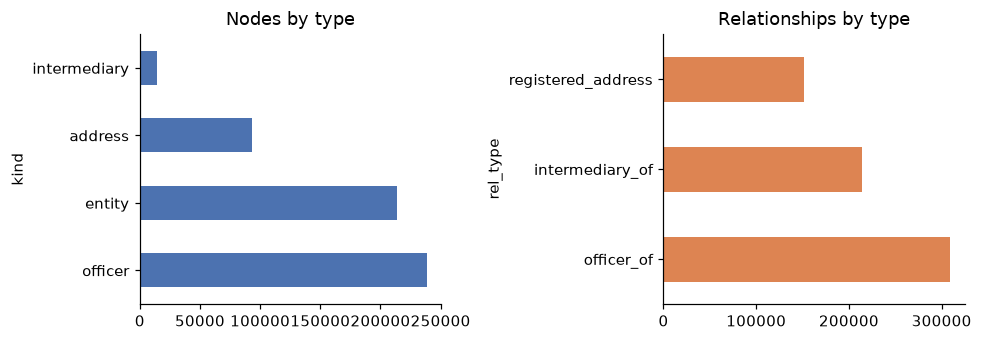

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
nodes.kind.value_counts().plot.barh(ax=ax[0], color="#4C72B0"); ax[0].set_title("Nodes by type")
rels.rel_type.value_counts().plot.barh(ax=ax[1], color="#DD8452"); ax[1].set_title("Relationships by type")
plt.tight_layout(); plt.savefig(FIG + "01_node_rel_types.png"); plt.show()

**Reading:** `registered_address` links are mostly officer -> address, so addresses add little to the entity graph.

In [7]:
d = edges_entity_connector(nodes, rels)
print("entity-connector links by connector type:"); print(d.groupby("ckind").size().to_string())

entity-connector links by connector type:
ckind
address           5310
intermediary    213634
officer         292743


## 3. Bipartite graph
Entities on one side, officers / intermediaries / addresses on the other. Undirected, simple.

In [8]:
B, P = pickle.load(open(PROC / "graphs.pkl", "rb"))  # built by src/run_stats.py
sB = stats(B, "bipartite"); print(json.dumps(sB, indent=1))

{
 "graph": "bipartite",
 "nodes": 468623,
 "edges": 511687,
 "type": "undirected simple",
 "density": 4.660023490239037e-06,
 "mean_degree": 2.183789528042798,
 "max_degree": 7016,
 "isolated": 0,
 "components": 12218,
 "largest_component": 310904,
 "largest_share": 0.6634416151149218,
 "top5_components": [
  310904,
  3642,
  2995,
  1468,
  1229
 ],
 "singleton_components": 0
}


### Bipartite graph in one picture

Two kinds of nodes, and links only between kinds. Entities are on one side, **connectors** (officers, intermediaries, addresses) on the other. Two entities are never linked directly: they are related through a shared connector.

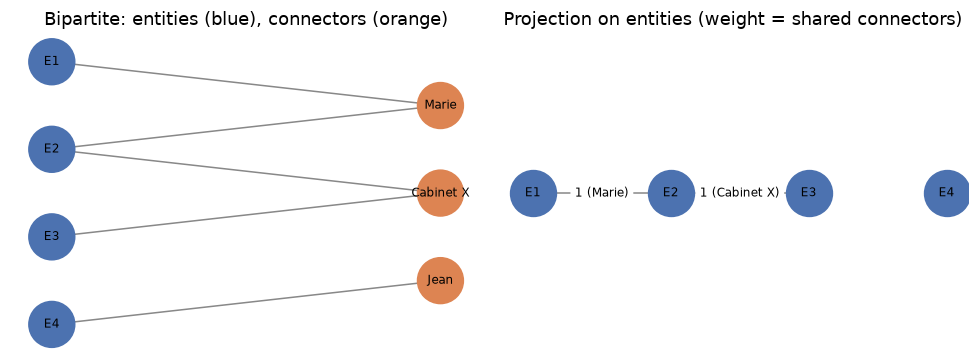

In [9]:
T = nx.Graph([("E1","Marie"),("E2","Marie"),("E2","Cabinet X"),("E3","Cabinet X"),("E4","Jean")])
ents = ["E1","E2","E3","E4"]; conns = ["Marie","Cabinet X","Jean"]
pos = {**{n: (0, -i) for i, n in enumerate(ents)}, **{n: (1, -i - 0.5) for i, n in enumerate(conns)}}
Tp = nx.Graph(); Tp.add_nodes_from(ents); Tp.add_edges_from([("E1","E2"),("E2","E3")])
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
nx.draw(T, pos, ax=ax[0], with_labels=True, node_size=900, font_size=8,
        node_color=["#4C72B0" if n in ents else "#DD8452" for n in T], edge_color="#888")
ax[0].set_title("Bipartite: entities (blue), connectors (orange)")
pp = {n: (i, 0) for i, n in enumerate(ents)}
nx.draw(Tp, pp, ax=ax[1], with_labels=True, node_size=900, font_size=8, node_color="#4C72B0", edge_color="#888")
nx.draw_networkx_edge_labels(Tp, pp, {("E1","E2"): "1 (Marie)", ("E2","E3"): "1 (Cabinet X)"}, ax=ax[1], font_size=8)
ax[1].set_title("Projection on entities (weight = shared connectors)")
plt.tight_layout(); plt.savefig(FIG + "01_toy_example.png"); plt.show()

- E1 and E2 share Marie, so they are linked with weight 1. E2 and E3 share Cabinet X.
- E4 is linked to Jean only, and Jean has no other entity, so E4 is **isolated** in the projection. This is why 61 % of entities are isolated in the real projection.
- **Cost of the projection:** a connector linked to `d` entities creates `d(d-1)/2` projected edges. Example: 6 entities give 15 edges, 7,016 give about 24.6 million.

In [10]:
print("6 entities ->", 6*5//2, "edges;  7016 entities ->", 7016*7015//2, "edges")

6 entities -> 15 edges;  7016 entities -> 24608620 edges


### A real piece of the network
One small connected component of the bipartite graph, with node types and entity jurisdictions (no personal names shown).

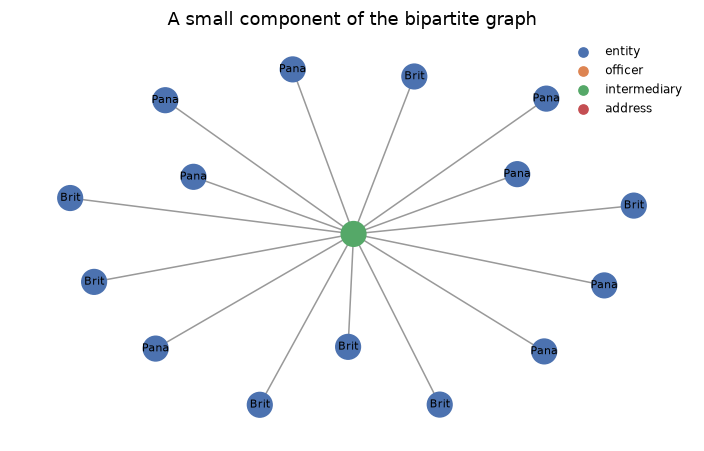

In [11]:
comps = [c for c in nx.connected_components(B) if 14 <= len(c) <= 18]
sub = B.subgraph(comps[0]); col = {"entity": "#4C72B0", "officer": "#DD8452", "intermediary": "#55A868", "address": "#C44E52"}
fig, ax = plt.subplots(figsize=(6.5, 4.2))
pos = nx.spring_layout(sub, seed=3)
nx.draw(sub, pos, ax=ax, node_color=[col[sub.nodes[n]["kind"]] for n in sub], node_size=260, edge_color="#999")
nx.draw_networkx_labels(sub, pos, {n: (sub.nodes[n].get("jur") or "")[:4] for n in sub if sub.nodes[n]["kind"] == "entity"}, font_size=7, ax=ax)
for k, c in col.items(): ax.scatter([], [], c=c, label=k)
ax.legend(frameon=False, fontsize=8); ax.set_title("A small component of the bipartite graph"); plt.tight_layout()
plt.savefig(FIG + "01_real_component.png"); plt.show()

## 4. Entity projection
Two entities are linked if they share a connector. Weight = number of shared connectors. Hubs are capped, otherwise a connector with `d` entities adds `d(d-1)/2` edges.

In [12]:
print("cap on connector degree:", CAP)
sP = stats(P, "projection"); print(json.dumps(sP, indent=1))
w = np.array([x for *_, x in P.edges(data="weight")])
print("edge weight: mean %.2f, max %d, share of weight-1 edges %.1f%%" % (w.mean(), w.max(), 100*(w==1).mean()))

cap on connector degree: {'officer': 500, 'intermediary': 50, 'address': 50}


{
 "graph": "projection",
 "nodes": 213634,
 "edges": 1238967,
 "type": "undirected simple, weighted",
 "density": 5.4293898082278016e-05,
 "mean_degree": 11.5989683290113,
 "max_degree": 720,
 "isolated": 129607,
 "components": 139643,
 "largest_component": 26643,
 "largest_share": 0.1247132947002818,
 "top5_components": [
  26643,
  132,
  126,
  121,
  115
 ],
 "singleton_components": 129607
}


edge weight: mean 1.17, max 73, share of weight-1 edges 83.8%


## 5. Summary table

In [13]:
tab = pd.DataFrame([sB, sP]).set_index("graph")[["nodes","edges","density","mean_degree","max_degree","components","largest_component","largest_share","isolated"]]
tab.T

graph,bipartite,projection
nodes,468623.000000,2.136340e+05
edges,511687.000000,1.238967e+06
density,0.000005,5.429390e-05
mean_degree,2.183790,1.159897e+01
max_degree,7016.000000,7.200000e+02
components,12218.000000,1.396430e+05
largest_component,310904.000000,2.664300e+04
largest_share,0.663442,1.247133e-01
isolated,0.000000,1.296070e+05


## 6. Degree distributions (log-log)

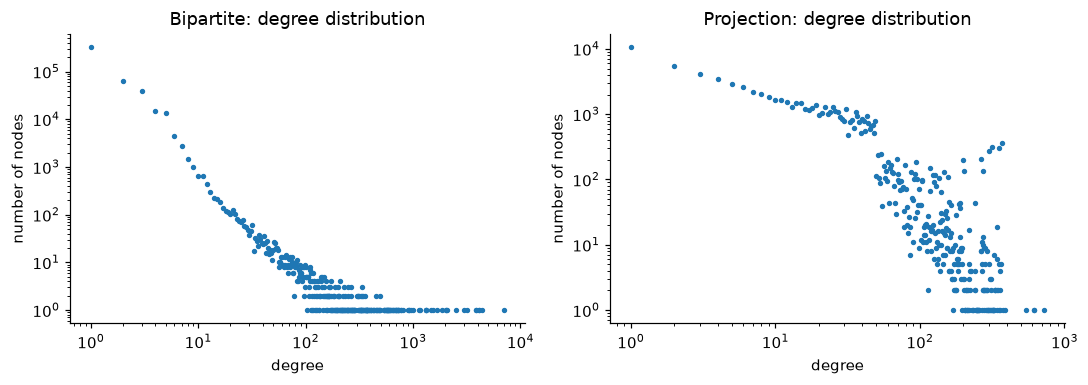

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for a, (G, t) in zip(ax, [(B, "Bipartite"), (P, "Projection")]):
    deg = np.array([x for _, x in G.degree()]); v, c = np.unique(deg[deg > 0], return_counts=True)
    a.loglog(v, c, ".", ms=5); a.set_title(t + ": degree distribution"); a.set_xlabel("degree"); a.set_ylabel("number of nodes")
plt.tight_layout(); plt.savefig(FIG + "01_degree_distributions.png"); plt.show()

## 7. Component sizes

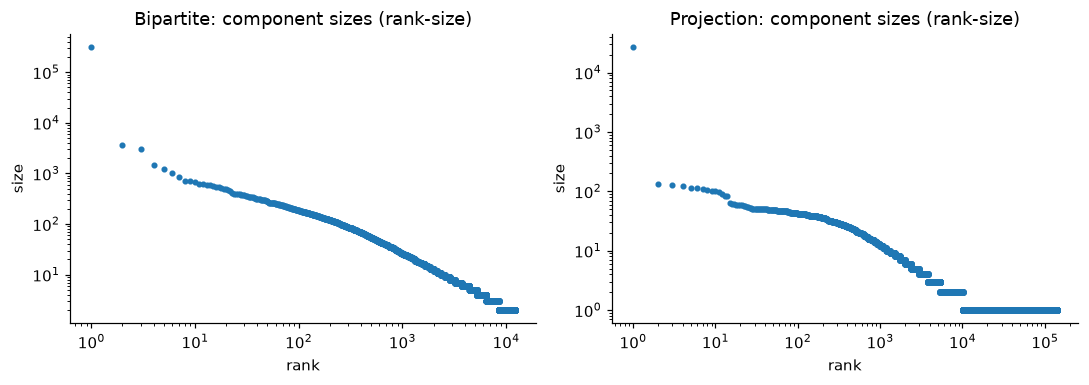

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for a, (G, t) in zip(ax, [(B, "Bipartite"), (P, "Projection")]):
    s = sorted((len(c) for c in nx.connected_components(G)), reverse=True)
    a.loglog(range(1, len(s)+1), s, "."); a.set_title(t + ": component sizes (rank-size)"); a.set_xlabel("rank"); a.set_ylabel("size")
plt.tight_layout(); plt.savefig(FIG + "01_component_sizes.png"); plt.show()

## 8. Conclusions and choices to justify in the report

- Heavy-tailed degrees: a few intermediaries and nominee officers act as hubs.
- The bipartite graph has one giant component (about 66 % of nodes) plus 12k small ones.
- The projection is fragmented: most entities are isolated because their connectors are shared by nobody, or exceed the cap.
- **Choices to defend:** Panama Papers only, undirected simple graph, caps (officers 500, intermediaries 50, addresses 50), centralities on the bipartite graph vs communities on the projection.
- **To test:** sensitivity of the intermediary cap (50, 100, 500).